In [1]:
from collections import deque
from pathlib import Path

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
import torch.optim as optim
from torch import nn
from tqdm import tqdm

## Hyperparameters

In [2]:
HIDDEN = 20
LEARNING_RATE = 0.01
EPISODES = 1000

GAMMA = 0.95  # baseline discount factor (given by the assignment)
GAMMA_BIG = 0.995  # bigger discount factor for the variants
ETA_MIN = 0.001  # final learning rate of the cosine scheduler

EVAL_EPISODES = 500
MOVING_AVERAGE_WINDOW = 100
SOLVED_THRESHOLD = 475  # CartPole-v1 counts as solved at a moving average of 475
RESET_OPTIONS = {"low": -0.15, "high": 0.15}
SEED = 0
SEEDS = [0, 1, 2, 3, 4]  # training seeds for the robustness experiment

FIGURES = Path("report/figures")

## Neural Net

In [3]:
class Policy(nn.Module):
    def __init__(self, hidden: int) -> None:
        super().__init__()
        self.ffw = nn.Sequential(nn.Linear(4, hidden), nn.ReLU(), nn.Linear(hidden, 1))

    def forward(self, x):
        return self.ffw(x)

## Training

In [4]:
def rewards_to_returns(rewards: list[float], gamma: float) -> torch.Tensor:
    returns = deque()
    R = 0
    for reward in reversed(rewards):
        R = reward + R * gamma
        returns.appendleft(R)

    return torch.Tensor(returns)


def shape_reward(reward: float, state) -> float:
    """Scale the reward by a Gaussian on the cart position, so staying centered pays more."""
    return (
        reward
        * torch.distributions.Normal(loc=0, scale=0.7)
        .log_prob(torch.tensor(state[0]))
        .exp()
        .item()
    )

In [5]:
def train(
    env: gym.Env,
    policy: nn.Module,
    optimizer: optim.Optimizer,
    episodes: int,
    gamma: float,
    scheduler: optim.lr_scheduler.LRScheduler | None = None,
    reward_shaping: bool = False,
    seed: int | None = None,
) -> list[float]:
    """Train `policy` with REINFORCE and return the (unshaped) reward of every episode."""
    if episodes <= 0:
        raise ValueError(f"episodes must be positive, got {episodes}")
    if not 0 < gamma <= 1:
        raise ValueError(f"gamma must be in (0, 1], got {gamma}")
    if scheduler is not None and scheduler.optimizer is not optimizer:
        raise ValueError("scheduler must wrap the given optimizer")

    policy.train()
    episode_rewards = []
    for episode in tqdm(range(episodes)):
        done = False
        state, _ = env.reset(seed=seed if episode == 0 else None, options=RESET_OPTIONS)
        log_probs, rewards = [], []
        episode_reward = 0.0
        while not done:
            logit = policy(torch.tensor(state))
            dist = torch.distributions.Bernoulli(F.sigmoid(logit))
            action = dist.sample()
            log_prob = dist.log_prob(action)

            state, reward, terminated, truncated, _ = env.step(int(action.item()))
            # Always report the true environment reward, the shaped one is only used for learning
            episode_reward += reward
            if reward_shaping:
                reward = shape_reward(reward, state)

            log_probs.append(log_prob)
            rewards.append(reward)
            done = terminated or truncated

        log_probs = torch.cat(log_probs)
        returns = rewards_to_returns(rewards, gamma)

        loss = -torch.sum(log_probs * returns)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        if scheduler is not None:
            scheduler.step()

        episode_rewards.append(episode_reward)

    return episode_rewards

In [ ]:
X_THRESHOLD = 2.4  # the cart leaves the track beyond |x| = 2.4
THETA_THRESHOLD = (
    12 * 2 * np.pi / 360
)  # the pole has fallen beyond |theta| = 12 degrees


def end_reason(state, terminated: bool) -> str:
    """Why an episode ended: the pole fell, the cart left the track, or the time limit was hit."""
    if not terminated:
        return "truncated"
    return "cart" if abs(state[0]) > X_THRESHOLD else "pole"


class EpisodeEndLogger(gym.Wrapper):
    """Record the end reason of every episode, without changing the environment."""

    def __init__(self, env: gym.Env) -> None:
        super().__init__(env)
        self.end_reasons = []

    def step(self, action):
        state, reward, terminated, truncated, info = self.env.step(action)
        if terminated or truncated:
            self.end_reasons.append(end_reason(state, terminated))
        return state, reward, terminated, truncated, info


def run_variant(
    gamma: float,
    use_scheduler: bool = False,
    reward_shaping: bool = False,
    seed: int = SEED,
    episodes: int = EPISODES,
    learning_rate: float = LEARNING_RATE,
    negate_reward: bool = False,
) -> tuple[nn.Module, list[float], list[str]]:
    """Build a fresh environment, policy, optimizer (and scheduler) and train them."""
    torch.manual_seed(seed)
    logger = EpisodeEndLogger(gym.make("CartPole-v1"))
    env = (
        gym.wrappers.TransformReward(logger, lambda r: -r) if negate_reward else logger
    )
    policy = Policy(HIDDEN)
    optimizer = optim.Adam(policy.parameters(), lr=learning_rate)
    scheduler = (
        optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=episodes, eta_min=ETA_MIN)
        if use_scheduler
        else None
    )

    rewards = train(
        env,
        policy,
        optimizer,
        episodes,
        gamma,
        scheduler=scheduler,
        reward_shaping=reward_shaping,
        seed=seed,
    )
    env.close()
    return policy, rewards, logger.end_reasons

## Evaluation and Plotting

In [ ]:
def rollout(
    env: gym.Env,
    policy: nn.Module,
    seed: int,
    greedy: bool = True,
    options=RESET_OPTIONS,
) -> tuple[np.ndarray, float, str]:
    """Play one episode and return the visited states, the total reward and why it ended."""
    state, _ = env.reset(seed=seed, options=options)
    states, total_reward, done = [state], 0.0, False
    while not done:
        with torch.no_grad():
            p_right = F.sigmoid(policy(torch.tensor(state))).item()
        action = int(p_right > 0.5) if greedy else int(torch.rand(1).item() < p_right)
        state, reward, terminated, truncated, _ = env.step(action)
        states.append(state)
        total_reward += reward
        done = terminated or truncated

    return np.array(states), total_reward, end_reason(state, terminated)


def evaluate(
    policy: nn.Module,
    episodes: int = EVAL_EPISODES,
    seed: int = SEED,
    greedy: bool = True,
    options=RESET_OPTIONS,
) -> dict[str, np.ndarray]:
    """Roll out the policy and return the reward, end reason and largest |x| of every episode."""
    env = gym.make("CartPole-v1")
    policy.eval()
    torch.manual_seed(seed)  # only used when actions are sampled
    rewards, ends, max_x = [], [], []
    for episode in tqdm(range(episodes)):
        states, reward, end = rollout(env, policy, seed + episode, greedy, options)
        rewards.append(reward)
        ends.append(end)
        max_x.append(np.abs(states[:, 0]).max())

    env.close()
    return {
        "reward": np.array(rewards),
        "end": np.array(ends),
        "max_x": np.array(max_x),
    }


def moving_average(
    values: list[float], window: int = MOVING_AVERAGE_WINDOW
) -> np.ndarray:
    """Trailing moving average; the first window-1 entries average over fewer episodes."""
    cumsum = np.cumsum(np.insert(np.asarray(values, dtype=float), 0, 0.0))
    counts = np.minimum(np.arange(1, len(values) + 1), window)
    ends = np.arange(1, len(values) + 1)
    return (cumsum[ends] - cumsum[ends - counts]) / counts


def episodes_to_solve(rewards: list[float]) -> int | None:
    """First episode at which the full-window moving average reaches the solved threshold."""
    average = moving_average(rewards)[MOVING_AVERAGE_WINDOW - 1 :]
    hits = np.flatnonzero(average >= SOLVED_THRESHOLD)
    return int(hits[0]) + MOVING_AVERAGE_WINDOW if hits.size else None


def save_figure(fig: plt.Figure, name: str) -> None:
    FIGURES.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIGURES / f"3a_{name}.png", dpi=150, bbox_inches="tight")


def plot_training(
    rewards: list[float],
    title: str,
    ax: plt.Axes | None = None,
    filename: str | None = None,
) -> None:
    standalone = ax is None
    if standalone:
        fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(rewards, alpha=0.4, label="Episode reward")
    ax.plot(
        moving_average(rewards),
        linewidth=2,
        label=f"Moving average ({MOVING_AVERAGE_WINDOW} episodes)",
    )
    ax.axhline(SOLVED_THRESHOLD, color="gray", linestyle=":", linewidth=1)
    ax.set(xlabel="Training episode", ylabel="Episode reward", title=title)
    ax.legend(loc="upper left")
    if standalone:
        if filename:
            save_figure(fig, filename)
        plt.show()


def plot_histogram(
    eval_rewards: np.ndarray, title: str, filename: str | None = None
) -> None:
    mean, std = eval_rewards.mean(), eval_rewards.std()
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.hist(eval_rewards, bins=30)
    ax.axvline(
        mean, color="black", linestyle="--", label=f"Mean = {mean:.1f}, std = {std:.1f}"
    )
    ax.set(
        xlabel="Episode reward",
        ylabel="Number of episodes",
        title=f"{title}: {len(eval_rewards)} evaluation episodes",
    )
    ax.legend()
    if filename:
        save_figure(fig, filename)
    plt.show()
    print(f"{title}: mean = {mean:.2f}, std = {std:.2f}")

## Baseline (no hyperparameter tricks)

Plain REINFORCE with $\gamma = 0.95$ (as given by the assignment), a constant learning rate and the raw environment reward.

In [ ]:
VARIANTS = {
    "Baseline (γ=0.95)": {"gamma": GAMMA},
    "γ=0.995": {"gamma": GAMMA_BIG},
    "γ=0.995 + scheduler": {"gamma": GAMMA_BIG, "use_scheduler": True},
    "γ=0.995 + scheduler + reward shaping": {
        "gamma": GAMMA_BIG,
        "use_scheduler": True,
        "reward_shaping": True,
    },
}
SLUGS = dict(zip(VARIANTS, ["baseline", "gamma", "scheduler", "shaping"]))
BASELINE, *_, FULL = VARIANTS

policies, train_rewards, train_ends, eval_results, eval_rewards = {}, {}, {}, {}, {}


def run_and_report(name: str) -> None:
    policies[name], train_rewards[name], train_ends[name] = run_variant(
        **VARIANTS[name]
    )
    plot_training(train_rewards[name], name, filename=f"training_{SLUGS[name]}")
    eval_results[name] = evaluate(policies[name])
    eval_rewards[name] = eval_results[name]["reward"]
    plot_histogram(eval_rewards[name], name, filename=f"histogram_{SLUGS[name]}")


  0%|          | 0/1000 [00:00<?, ?it/s]


  0%|          | 1/1000 [00:00<02:10,  7.64it/s]


  1%|          | 12/1000 [00:00<00:16, 59.79it/s]


  2%|▏         | 23/1000 [00:00<00:12, 79.48it/s]


  3%|▎         | 32/1000 [00:00<00:11, 80.93it/s]

...


100%|█████████▉| 997/1000 [01:06<00:00,  4.94it/s]


100%|█████████▉| 998/1000 [01:06<00:00,  4.99it/s]


100%|█████████▉| 999/1000 [01:07<00:00,  4.90it/s]


100%|██████████| 1000/1000 [01:07<00:00,  4.94it/s]


100%|██████████| 1000/1000 [01:07<00:00, 14.84it/s]

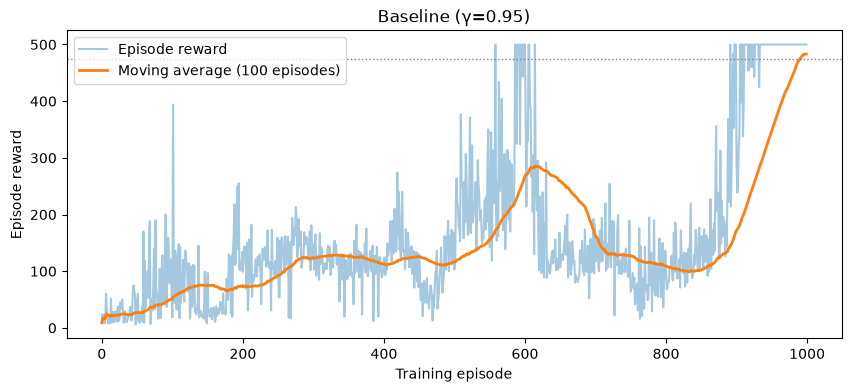


  0%|          | 0/500 [00:00<?, ?it/s]


  1%|          | 3/500 [00:00<00:17, 28.58it/s]


  1%|          | 6/500 [00:00<00:16, 29.30it/s]


  2%|▏         | 9/500 [00:00<00:16, 29.12it/s]


  3%|▎         | 13/500 [00:00<00:16, 29.89it/s]

...


 98%|█████████▊| 489/500 [00:16<00:00, 29.94it/s]


 98%|█████████▊| 492/500 [00:16<00:00, 29.79it/s]


 99%|█████████▉| 495/500 [00:17<00:00, 28.79it/s]


100%|█████████▉| 498/500 [00:17<00:00, 28.93it/s]


100%|██████████| 500/500 [00:17<00:00, 28.99it/s]

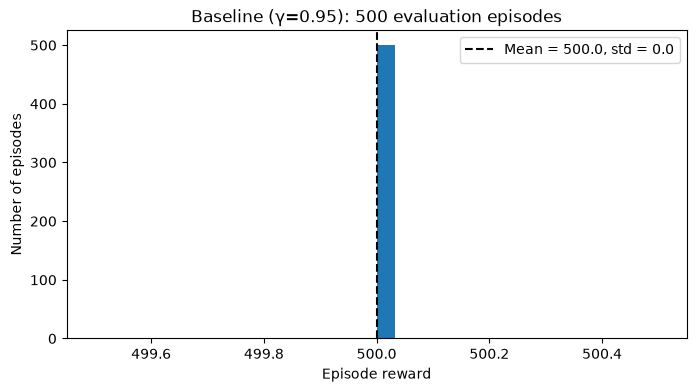

Baseline (γ=0.95): mean = 500.00, std = 0.00


In [9]:
run_and_report("Baseline (γ=0.95)")

## Variant 1: Bigger discount factor

Same as the baseline, but with $\gamma = 0.995$.


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 12/1000 [00:00<00:08, 113.35it/s]


  2%|▎         | 25/1000 [00:00<00:07, 121.88it/s]


  4%|▍         | 38/1000 [00:00<00:08, 111.83it/s]


  5%|▌         | 50/1000 [00:00<00:09, 103.90it/s]

...


100%|█████████▉| 997/1000 [02:21<00:00,  4.97it/s]


100%|█████████▉| 998/1000 [02:21<00:00,  4.97it/s]


100%|█████████▉| 999/1000 [02:21<00:00,  4.97it/s]


100%|██████████| 1000/1000 [02:21<00:00,  4.98it/s]


100%|██████████| 1000/1000 [02:21<00:00,  7.05it/s]

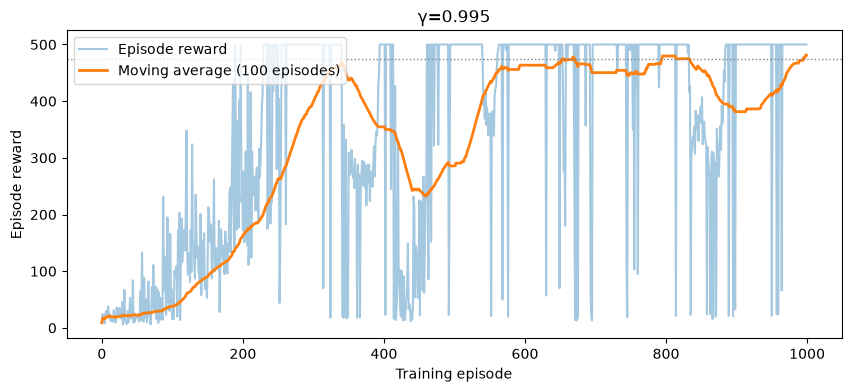


  0%|          | 0/500 [00:00<?, ?it/s]


  1%|          | 3/500 [00:00<00:16, 29.39it/s]


  1%|          | 6/500 [00:00<00:16, 29.50it/s]


  2%|▏         | 9/500 [00:00<00:16, 29.56it/s]


  2%|▏         | 12/500 [00:00<00:16, 28.76it/s]

...


 98%|█████████▊| 489/500 [00:17<00:00, 29.93it/s]


 98%|█████████▊| 492/500 [00:17<00:00, 29.77it/s]


 99%|█████████▉| 495/500 [00:17<00:00, 29.70it/s]


100%|█████████▉| 498/500 [00:17<00:00, 29.27it/s]


100%|██████████| 500/500 [00:17<00:00, 28.75it/s]

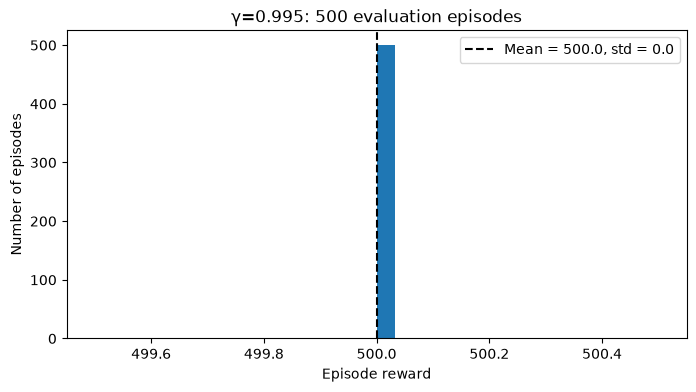

γ=0.995: mean = 500.00, std = 0.00


In [10]:
run_and_report("γ=0.995")

## Variant 2: + Learning-rate scheduler

$\gamma = 0.995$ and a cosine annealing scheduler that decays the learning rate from 0.01 to 0.001.


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 12/1000 [00:00<00:08, 118.50it/s]


  2%|▎         | 25/1000 [00:00<00:07, 121.93it/s]


  4%|▍         | 38/1000 [00:00<00:08, 107.25it/s]


  5%|▍         | 49/1000 [00:00<00:09, 102.42it/s]

...


100%|█████████▉| 997/1000 [02:13<00:00,  5.07it/s]


100%|█████████▉| 998/1000 [02:14<00:00,  5.09it/s]


100%|█████████▉| 999/1000 [02:14<00:00,  5.11it/s]


100%|██████████| 1000/1000 [02:14<00:00,  5.11it/s]


100%|██████████| 1000/1000 [02:14<00:00,  7.44it/s]

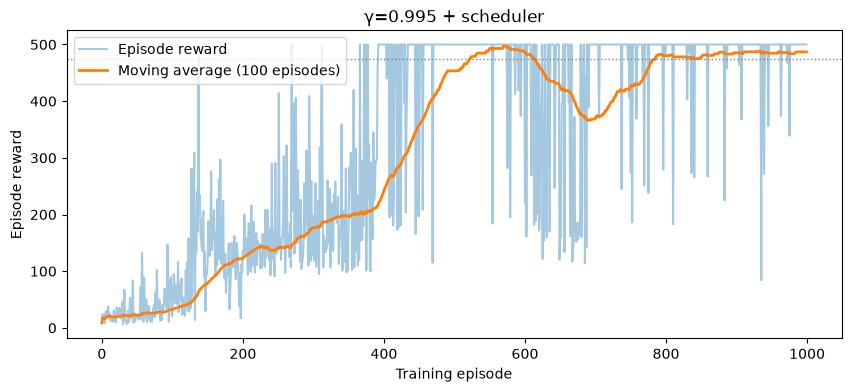


  0%|          | 0/500 [00:00<?, ?it/s]


  1%|          | 3/500 [00:00<00:16, 29.85it/s]


  1%|          | 6/500 [00:00<00:16, 29.59it/s]


  2%|▏         | 9/500 [00:00<00:17, 28.38it/s]


  2%|▏         | 12/500 [00:00<00:17, 28.41it/s]

...


 98%|█████████▊| 489/500 [00:16<00:00, 29.45it/s]


 98%|█████████▊| 492/500 [00:16<00:00, 29.53it/s]


 99%|█████████▉| 495/500 [00:17<00:00, 29.33it/s]


100%|█████████▉| 499/500 [00:17<00:00, 29.65it/s]


100%|██████████| 500/500 [00:17<00:00, 29.07it/s]

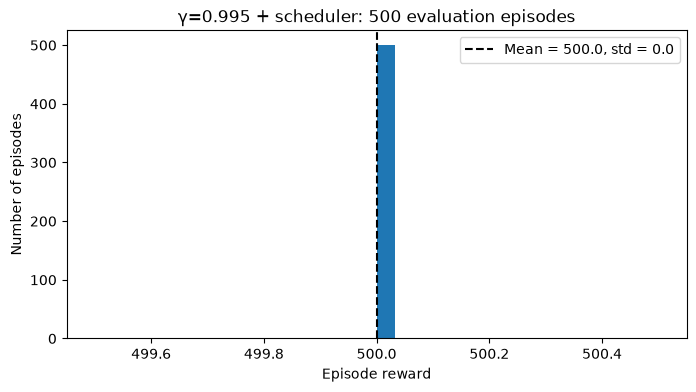

γ=0.995 + scheduler: mean = 500.00, std = 0.00


In [11]:
run_and_report("γ=0.995 + scheduler")

## Variant 3: + Reward shaping

$\gamma = 0.995$, cosine scheduler and reward shaping: each reward is scaled by a Gaussian density on the cart position
($\sigma = 0.7$), so the agent is rewarded more for staying close to the center.
The plotted rewards are still the unshaped environment rewards, so all variants are comparable.


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:10, 92.55it/s]


  2%|▏         | 22/1000 [00:00<00:09, 102.85it/s]


  3%|▎         | 33/1000 [00:00<00:11, 82.41it/s] 


  4%|▍         | 43/1000 [00:00<00:11, 86.55it/s]

...


100%|█████████▉| 997/1000 [03:41<00:00,  3.92it/s]


100%|█████████▉| 998/1000 [03:41<00:00,  3.95it/s]


100%|█████████▉| 999/1000 [03:41<00:00,  3.96it/s]


100%|██████████| 1000/1000 [03:41<00:00,  3.91it/s]


100%|██████████| 1000/1000 [03:41<00:00,  4.51it/s]

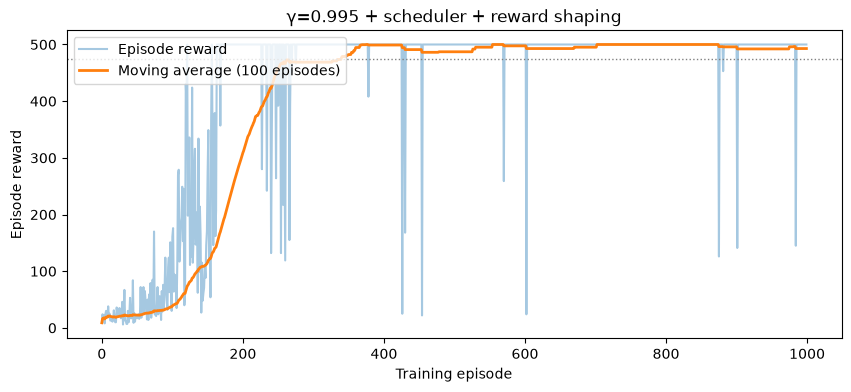


  0%|          | 0/500 [00:00<?, ?it/s]


  1%|          | 3/500 [00:00<00:16, 29.51it/s]


  1%|          | 6/500 [00:00<00:16, 29.32it/s]


  2%|▏         | 9/500 [00:00<00:16, 29.04it/s]


  2%|▏         | 12/500 [00:00<00:16, 29.00it/s]

...


 98%|█████████▊| 489/500 [00:16<00:00, 29.61it/s]


 98%|█████████▊| 492/500 [00:16<00:00, 29.15it/s]


 99%|█████████▉| 495/500 [00:16<00:00, 29.21it/s]


100%|█████████▉| 498/500 [00:17<00:00, 28.57it/s]


100%|██████████| 500/500 [00:17<00:00, 29.21it/s]

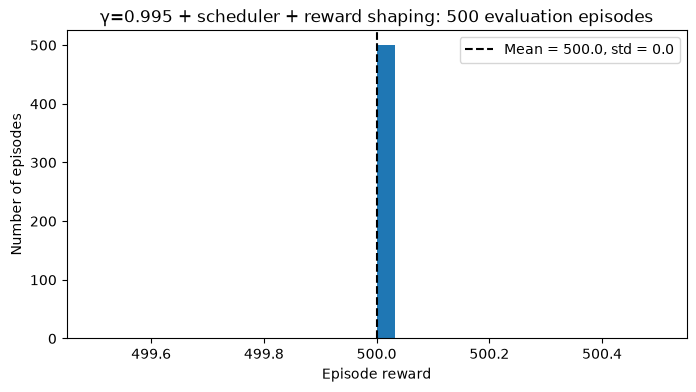

γ=0.995 + scheduler + reward shaping: mean = 500.00, std = 0.00


In [12]:
run_and_report("γ=0.995 + scheduler + reward shaping")

## Comparison

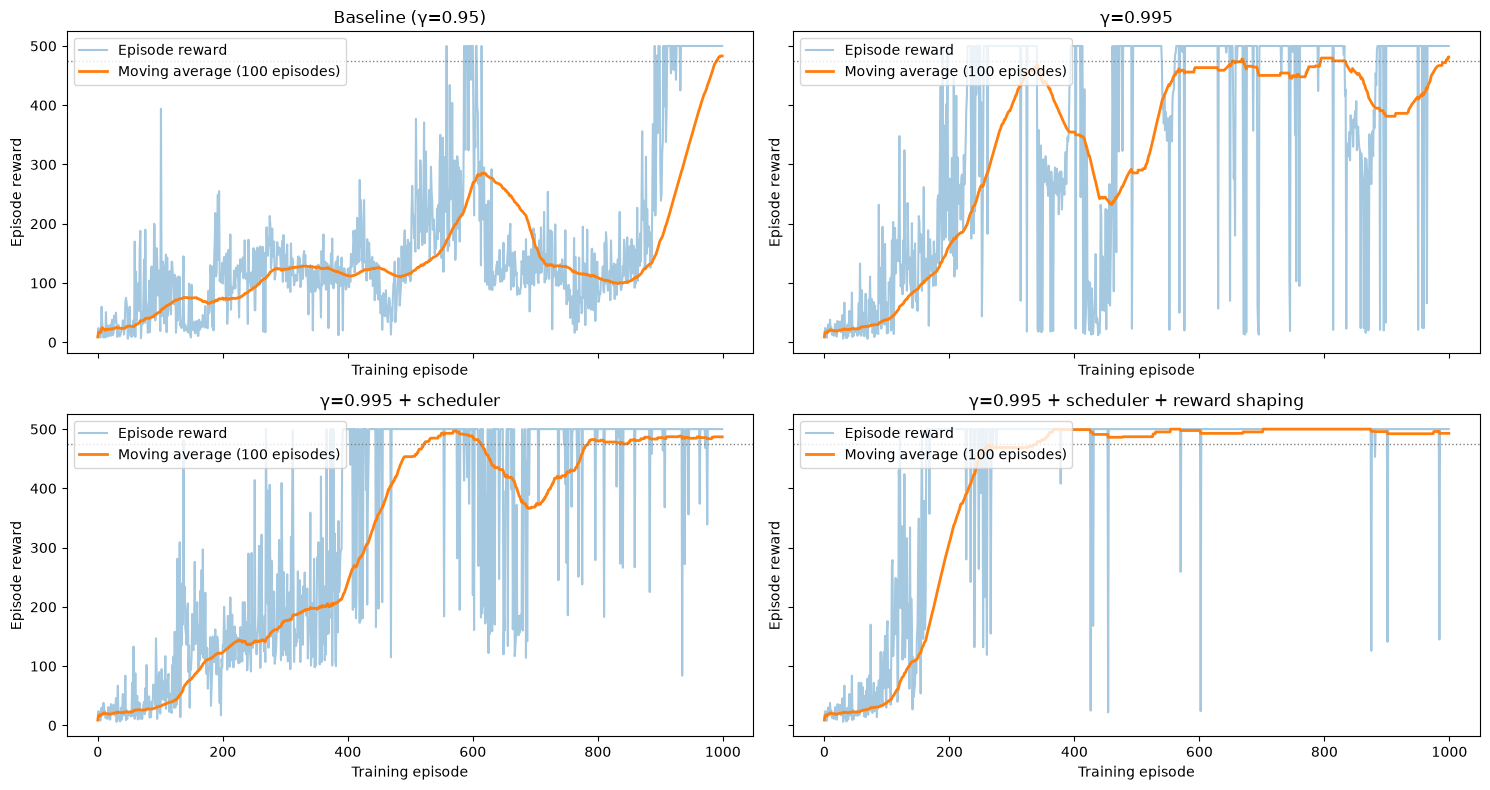

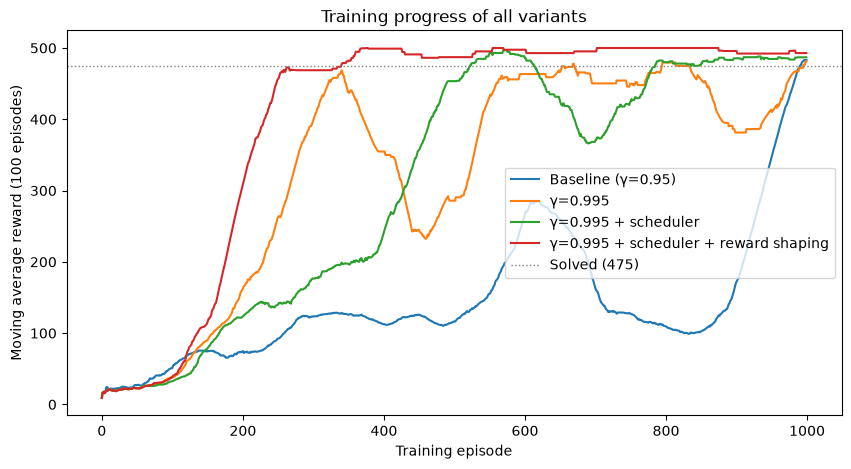

Variant                                  Solved at  Train mean  Last 100  Eval mean  Eval std
Baseline (γ=0.95)                              991       167.0     483.1     500.00      0.00
γ=0.995                                        669       349.2     481.4     500.00      0.00
γ=0.995 + scheduler                            523       333.2     486.9     500.00      0.00
γ=0.995 + scheduler + reward shaping           341       427.9     492.9     500.00      0.00


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(15, 8), sharex=True, sharey=True)
for ax, (name, rewards) in zip(axes.flat, train_rewards.items()):
    plot_training(rewards, name, ax=ax)
fig.tight_layout()
save_figure(fig, "training_variants")
plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
for name, rewards in train_rewards.items():
    ax.plot(moving_average(rewards), label=name)
ax.axhline(
    SOLVED_THRESHOLD, color="gray", linestyle=":", linewidth=1, label="Solved (475)"
)
ax.set(
    xlabel="Training episode",
    ylabel=f"Moving average reward ({MOVING_AVERAGE_WINDOW} episodes)",
    title="Training progress of all variants",
)
ax.legend()
save_figure(fig, "moving_averages")
plt.show()

print(
    f"{'Variant':<40}{'Solved at':>10}{'Train mean':>12}{'Last 100':>10}{'Eval mean':>11}{'Eval std':>10}"
)
for name, rewards in train_rewards.items():
    solved = episodes_to_solve(rewards)
    print(
        f"{name:<40}{solved if solved else 'never':>10}{np.mean(rewards):>12.1f}"
        f"{np.mean(rewards[-MOVING_AVERAGE_WINDOW:]):>10.1f}"
        f"{eval_rewards[name].mean():>11.2f}{eval_rewards[name].std():>10.2f}"
    )

## Robustness Across Training Seeds

A single training run can be lucky or unlucky, so every variant is trained again with 4 more seeds (seed 0 is the run above).
Each trained policy is evaluated greedily on the first 100 of the 500 evaluation start states.
**Expected:** if the hyperparameters really help, the advantage shows up across seeds, not only for seed 0.
This cell takes about 45 minutes.

In [ ]:
SEED_EVAL_EPISODES = 100

seed_rewards = {name: {SEED: train_rewards[name]} for name in VARIANTS}
seed_evals = {
    name: {SEED: eval_rewards[name][:SEED_EVAL_EPISODES]} for name in VARIANTS
}
for seed in SEEDS:
    if seed == SEED:
        continue
    for name, kwargs in VARIANTS.items():
        policy, rewards, _ = run_variant(**kwargs, seed=seed)
        seed_rewards[name][seed] = rewards
        seed_evals[name][seed] = evaluate(policy, episodes=SEED_EVAL_EPISODES)["reward"]


  0%|          | 0/1000 [00:00<?, ?it/s]


  2%|▏         | 15/1000 [00:00<00:07, 132.05it/s]


  3%|▎         | 29/1000 [00:00<00:07, 132.66it/s]


  4%|▍         | 43/1000 [00:00<00:07, 123.07it/s]


  6%|▌         | 56/1000 [00:00<00:07, 118.59it/s]

...


 90%|█████████ | 90/100 [00:03<00:00, 27.82it/s]


 93%|█████████▎| 93/100 [00:03<00:00, 27.70it/s]


 96%|█████████▌| 96/100 [00:03<00:00, 27.79it/s]


 99%|█████████▉| 99/100 [00:03<00:00, 27.86it/s]


100%|██████████| 100/100 [00:03<00:00, 27.94it/s]

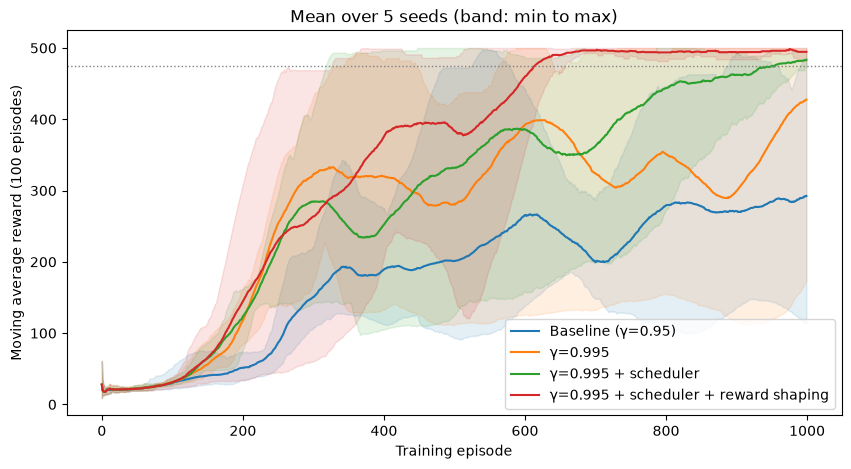

Variant                                             Solved at (per seed)      Train mean      Last 100  Eval mean  Eval = 500
Baseline (γ=0.95)                                      991, 525, -, -, -    192.8 ± 60.4  292.4 ± 138.0      362.0         3/5
γ=0.995                                            669, 333, 395, -, 662    286.3 ± 78.3  427.6 ± 127.6      462.2         4/5
γ=0.995 + scheduler                              523, 753, 806, 319, 995    315.6 ± 65.3  483.6 ± 7.4       497.7         4/5
γ=0.995 + scheduler + reward shaping             341, 327, 659, 494, 604    363.3 ± 48.3  494.6 ± 6.8       500.0         5/5


In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
for name in VARIANTS:
    curves = np.array([moving_average(r) for r in seed_rewards[name].values()])
    (line,) = ax.plot(curves.mean(axis=0), label=name)
    ax.fill_between(
        np.arange(EPISODES),
        curves.min(axis=0),
        curves.max(axis=0),
        color=line.get_color(),
        alpha=0.12,
    )
ax.axhline(SOLVED_THRESHOLD, color="gray", linestyle=":", linewidth=1)
ax.set(
    xlabel="Training episode",
    ylabel=f"Moving average reward ({MOVING_AVERAGE_WINDOW} episodes)",
    title=f"Mean over {len(SEEDS)} seeds (band: min to max)",
)
ax.legend()
save_figure(fig, "seeds")
plt.show()

print(
    f"{'Variant':<40}{'Solved at (per seed)':>32}{'Train mean':>16}{'Last 100':>14}{'Eval mean':>11}{'Eval = 500':>12}"
)
for name in VARIANTS:
    rewards = list(seed_rewards[name].values())
    solved = [episodes_to_solve(r) for r in rewards]
    train_means = [np.mean(r) for r in rewards]
    last_100 = [np.mean(r[-MOVING_AVERAGE_WINDOW:]) for r in rewards]
    evals = np.array([e.mean() for e in seed_evals[name].values()])
    print(
        f"{name:<40}{', '.join(str(s) if s else '-' for s in solved):>32}"
        f"{np.mean(train_means):>9.1f} ± {np.std(train_means):<4.1f}"
        f"{np.mean(last_100):>7.1f} ± {np.std(last_100):<4.1f}"
        f"{evals.mean():>11.1f}{f'{np.sum(evals == 500)}/{len(evals)}':>12}"
    )

## Checks

Each check prints `[PASS]` / `[FAIL]`. The checks reuse the trained policies from above.

In [14]:
def report(name: str, passed: bool) -> None:
    print(f"[{'PASS' if passed else 'FAIL'}] {name}")

### Check 1: Discounted Returns and the Credit Horizon

For a constant reward of 1 per step, the return has the closed form $G_t = \frac{1 - \gamma^{T-t}}{1 - \gamma}$; with $\gamma = 1$ it is the number of remaining steps,
and a single reward at the last step is worth $\gamma^{T-1-t}$ at step $t$. **Expected:** `rewards_to_returns` matches all three exactly.

The plots show how far each discount factor looks ahead. A reward $k$ steps in the future is weighted with $\gamma^k$, so $\gamma = 0.95$ effectively only sees
$1/(1-\gamma) = 20$ steps ahead. **Expected:** with $\gamma = 0.95$, an episode that fails at step 400 and one that survives all 500 steps give
(almost) the same returns for the first ~300 steps, i.e. a slow drift that only causes a failure much later is barely punished.

[PASS] γ = 0.95: constant reward gives G_t = (1 - γ^(T-t)) / (1 - γ)
[PASS] γ = 0.95: a single final reward is worth γ^(T-1-t)
[PASS] γ = 0.995: constant reward gives G_t = (1 - γ^(T-t)) / (1 - γ)
[PASS] γ = 0.995: a single final reward is worth γ^(T-1-t)
[PASS] γ = 1: G_t = number of remaining steps
γ = 0.95: effective horizon 1/(1-γ) = 20 steps, γ^100 = 0.006
γ = 0.99: effective horizon 1/(1-γ) = 100 steps, γ^100 = 0.366
γ = 0.995: effective horizon 1/(1-γ) = 200 steps, γ^100 = 0.606


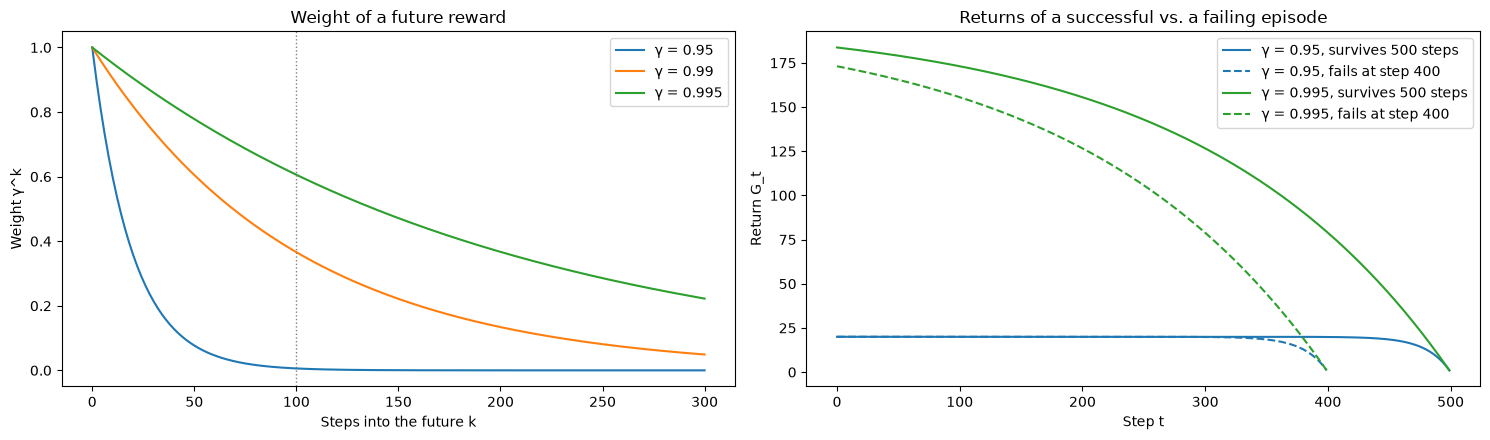

In [ ]:
T = 500
t = np.arange(T)
ones = [1.0] * T
for gamma in (GAMMA, GAMMA_BIG):
    report(
        f"γ = {gamma}: constant reward gives G_t = (1 - γ^(T-t)) / (1 - γ)",
        np.allclose(
            rewards_to_returns(ones, gamma).numpy(),
            (1 - gamma ** (T - t)) / (1 - gamma),
            rtol=1e-4,
        ),
    )
    report(
        f"γ = {gamma}: a single final reward is worth γ^(T-1-t)",
        np.allclose(
            rewards_to_returns([0.0] * (T - 1) + [1.0], gamma).numpy(),
            gamma ** (T - 1 - t),
            rtol=1e-4,
        ),
    )
report(
    "γ = 1: G_t = number of remaining steps",
    np.allclose(rewards_to_returns(ones, 1.0).numpy(), T - t),
)

for gamma in (GAMMA, 0.99, GAMMA_BIG):
    print(
        f"γ = {gamma}: effective horizon 1/(1-γ) = {1 / (1 - gamma):.0f} steps, γ^100 = {gamma**100:.3f}"
    )

fig, (ax_w, ax_g) = plt.subplots(1, 2, figsize=(15, 4.5))
k = np.arange(301)
for gamma in (GAMMA, 0.99, GAMMA_BIG):
    ax_w.plot(k, gamma**k, label=f"γ = {gamma}")
ax_w.axvline(100, color="gray", linestyle=":", linewidth=1)
ax_w.set(
    xlabel="Steps into the future k",
    ylabel="Weight γ^k",
    title="Weight of a future reward",
)
ax_w.legend()

for gamma, color in ((GAMMA, "C0"), (GAMMA_BIG, "C2")):
    ax_g.plot(
        rewards_to_returns(ones, gamma).numpy(),
        color=color,
        label=f"γ = {gamma}, survives 500 steps",
    )
    ax_g.plot(
        rewards_to_returns([1.0] * 400, gamma).numpy(),
        color=color,
        linestyle="--",
        label=f"γ = {gamma}, fails at step 400",
    )
ax_g.set(
    xlabel="Step t",
    ylabel="Return G_t",
    title="Returns of a successful vs. a failing episode",
)
ax_g.legend()
fig.tight_layout()
save_figure(fig, "discounting")
plt.show()

### Check 2: Control Experiments

Three short trainings (300 episodes, $\gamma = 0.95$) that only differ in the learning signal, compared with two fixed reference policies:
a uniformly random policy, and always pushing in the same direction, which is the simplest way to make the pole fall as fast as possible.
- **Normal:** **expected:** the episode length clearly increases (more than doubles).
- **No learning (learning rate 0):** the policy never changes. **Expected:** the episode length stays flat at the level of the untrained network.
- **Negated reward (−1 per step):** maximising the return now means failing as fast as possible. **Expected:** the episode length drops below
  the random policy, towards the "always push in one direction" reference. This confirms that the gradient points in the right direction:
  the same code learns the opposite behaviour when the reward is flipped.


  0%|          | 0/300 [00:00<?, ?it/s]


  4%|▍         | 12/300 [00:00<00:02, 115.99it/s]


  8%|▊         | 24/300 [00:00<00:02, 107.24it/s]


 12%|█▏        | 35/300 [00:00<00:02, 100.81it/s]


 15%|█▌        | 46/300 [00:00<00:02, 89.28it/s] 

...


 79%|███████▊  | 236/300 [00:01<00:00, 218.80it/s]


 86%|████████▋ | 259/300 [00:01<00:00, 219.80it/s]


 94%|█████████▍| 282/300 [00:01<00:00, 216.34it/s]


100%|██████████| 300/300 [00:01<00:00, 193.02it/s]

Normal                : first 100 =   50.9, last 100 =  123.2
No learning (lr = 0)  : first 100 =   20.9, last 100 =   21.7
Negated reward        : first 100 =   15.4, last 100 =   10.2
Random policy         : mean = 19.9 over 500 episodes
Always one direction  : mean = 9.3 over 500 episodes
[PASS] Normal training: last 100 episodes more than 2x longer than the first 100
[PASS] No learning: the two halves differ by less than 30%
[PASS] Negated reward: last 100 episodes shorter than random and within 20% of always pushing in one direction


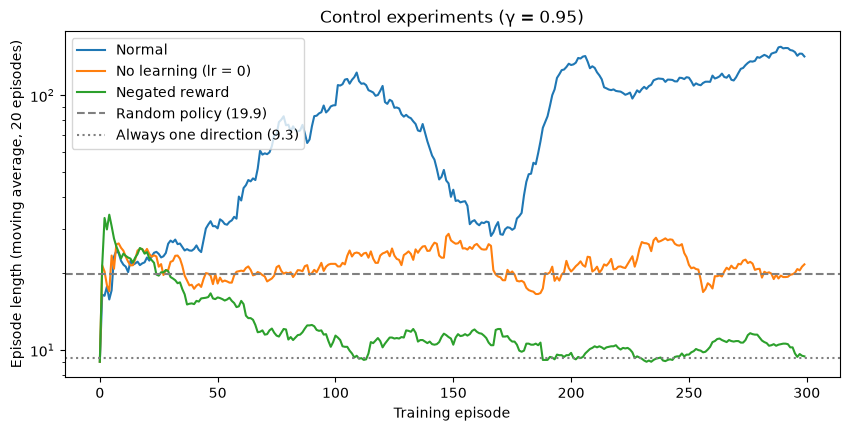

In [ ]:
CHECK_EPISODES = 300

controls = {
    "Normal": {},
    "No learning (lr = 0)": {"learning_rate": 0.0},
    "Negated reward": {"negate_reward": True},
}
control_lengths = {}
for label, kwargs in controls.items():
    _, rewards, _ = run_variant(GAMMA, episodes=CHECK_EPISODES, **kwargs)
    control_lengths[label] = np.abs(
        rewards
    )  # every step gives +-1, so |reward| is the length


def reference_lengths(choose_action) -> np.ndarray:
    """Episode lengths of a fixed policy on the evaluation start states."""
    env = gym.make("CartPole-v1")
    env.action_space.seed(SEED)
    lengths = []
    for episode in range(EVAL_EPISODES):
        env.reset(seed=SEED + episode, options=RESET_OPTIONS)
        length, done = 0, False
        while not done:
            _, _, terminated, truncated, _ = env.step(choose_action(env))
            length, done = length + 1, terminated or truncated
        lengths.append(length)
    return np.array(lengths)


random_mean = reference_lengths(lambda env: env.action_space.sample()).mean()
one_direction_mean = np.mean(
    [reference_lengths(lambda env, a=a: a).mean() for a in (0, 1)]
)

for label, lengths in control_lengths.items():
    print(
        f"{label:<22}: first 100 = {lengths[:100].mean():6.1f}, last 100 = {lengths[-100:].mean():6.1f}"
    )
print(f"{'Random policy':<22}: mean = {random_mean:.1f} over {EVAL_EPISODES} episodes")
print(
    f"{'Always one direction':<22}: mean = {one_direction_mean:.1f} over {EVAL_EPISODES} episodes"
)

normal, frozen, negated = control_lengths.values()
report(
    "Normal training: last 100 episodes more than 2x longer than the first 100",
    normal[-100:].mean() > 2 * normal[:100].mean(),
)
report(
    "No learning: the two halves differ by less than 30%",
    abs(frozen[150:].mean() - frozen[:150].mean()) < 0.3 * frozen[:150].mean(),
)
report(
    "Negated reward: last 100 episodes shorter than random and within 20% of always pushing in one direction",
    negated[-100:].mean() < random_mean
    and negated[-100:].mean() < 1.2 * one_direction_mean,
)

fig, ax = plt.subplots(figsize=(10, 4.5))
for label, lengths in control_lengths.items():
    ax.plot(moving_average(lengths, 20), label=label)
ax.axhline(
    random_mean,
    color="gray",
    linestyle="--",
    label=f"Random policy ({random_mean:.1f})",
)
ax.axhline(
    one_direction_mean,
    color="gray",
    linestyle=":",
    label=f"Always one direction ({one_direction_mean:.1f})",
)
ax.set(
    xlabel="Training episode",
    ylabel="Episode length (moving average, 20 episodes)",
    title="Control experiments (γ = 0.95)",
    yscale="log",
)
ax.legend()
save_figure(fig, "control_experiments")
plt.show()

### Check 3: First 10 Steps

One episode with the trained baseline policy, with actions sampled from the policy as during training. For every step: the state
(cart position $x$, cart velocity $\dot x$, pole angle $\theta$, pole angular velocity $\dot\theta$), the probability of pushing right, the sampled action,
the environment reward and the shaped reward. **Expected:**
- To bring the pole back up, the cart has to move under it, so the policy mostly pushes towards the side the pole leans to ($\theta < 0$ → left).
  It only becomes unsure when the pole is already swinging back quickly ($\dot\theta$ against $\theta$).
- As a result, $|\theta|$ decreases over the 10 steps.
- The shaped reward stays close to its maximum $1/(0.7\sqrt{2\pi}) = 0.570$ while the cart is near the center.

In [ ]:
FIRST_STEPS = 10

policy = policies[BASELINE]
policy.eval()
env = gym.make("CartPole-v1")
state, _ = env.reset(seed=SEED, options=RESET_OPTIONS)
torch.manual_seed(SEED)

print(
    f"{'t':>2}{'x':>8}{'x_dot':>8}{'theta':>8}{'th_dot':>8}{'P(right)':>10}{'action':>8}{'reward':>8}{'shaped':>8}"
)
first_theta = state[2]
towards_lean = []
for step in range(FIRST_STEPS):
    with torch.no_grad():
        p_right = F.sigmoid(policy(torch.tensor(state))).item()
    action = int(torch.rand(1).item() < p_right)
    next_state, reward, terminated, truncated, _ = env.step(action)
    print(
        f"{step:>2}{state[0]:>8.3f}{state[1]:>8.3f}{state[2]:>8.3f}{state[3]:>8.3f}"
        f"{p_right:>10.3f}{'right' if action else 'left':>8}{reward:>8.1f}{shape_reward(reward, next_state):>8.3f}"
    )
    towards_lean.append((p_right > 0.5) == (state[2] > 0))
    state = next_state

report(
    f"The more likely action pushes towards the side the pole leans to in {sum(towards_lean)}/{FIRST_STEPS} steps",
    sum(towards_lean) >= 0.8 * FIRST_STEPS,
)
report(
    f"The pole is brought back up: |theta| {abs(first_theta):.3f} -> {abs(state[2]):.3f}",
    abs(state[2]) < abs(first_theta),
)

 t       x   x_dot   theta  th_dot  P(right)  action  reward  shaped
 0   0.041  -0.069  -0.138  -0.145     0.026    left     1.0   0.569
 1   0.040  -0.262  -0.141   0.101     0.050    left     1.0   0.569
 2   0.034  -0.455  -0.139   0.346     0.143   right     1.0   0.570
 3   0.025  -0.258  -0.132   0.013     0.030    left     1.0   0.570
 4   0.020  -0.451  -0.131   0.262     0.076    left     1.0   0.570
 5   0.011  -0.644  -0.126   0.510     0.239    left     1.0   0.570
 6  -0.002  -0.837  -0.116   0.761     0.585   right     1.0   0.570
 7  -0.018  -0.641  -0.101   0.434     0.162    left     1.0   0.569
 8  -0.031  -0.834  -0.092   0.693     0.481   right     1.0   0.569
 9  -0.048  -0.638  -0.078   0.373     0.121    left     1.0   0.568
[PASS] The more likely action pushes towards the side the pole leans to in 9/10 steps
[PASS] The pole is brought back up: |theta| 0.138 -> 0.071


### Check 4: Does the Policy React Correctly to the Pole?

To balance the pole, the cart must move under it: if the pole leans or falls to the right ($\theta > 0$ or $\dot\theta > 0$), the policy should push right.
I vary $\theta$ and $\dot\theta$ one at a time (all other state variables 0) and record $P(\text{right})$ for every trained policy.
**Expected:** $P(\text{right})$ increases with both, below 0.5 for negative and above 0.5 for positive values.

[PASS] Baseline (γ=0.95): P(right) increases with theta, < 0.5 at -0.21 and > 0.5 at 0.21
[PASS] γ=0.995: P(right) increases with theta, < 0.5 at -0.21 and > 0.5 at 0.21
[PASS] γ=0.995 + scheduler: P(right) increases with theta, < 0.5 at -0.21 and > 0.5 at 0.21
[PASS] γ=0.995 + scheduler + reward shaping: P(right) increases with theta, < 0.5 at -0.21 and > 0.5 at 0.21
[PASS] Baseline (γ=0.95): P(right) increases with theta_dot, < 0.5 at -2.00 and > 0.5 at 2.00
[PASS] γ=0.995: P(right) increases with theta_dot, < 0.5 at -2.00 and > 0.5 at 2.00
[PASS] γ=0.995 + scheduler: P(right) increases with theta_dot, < 0.5 at -2.00 and > 0.5 at 2.00
[PASS] γ=0.995 + scheduler + reward shaping: P(right) increases with theta_dot, < 0.5 at -2.00 and > 0.5 at 2.00


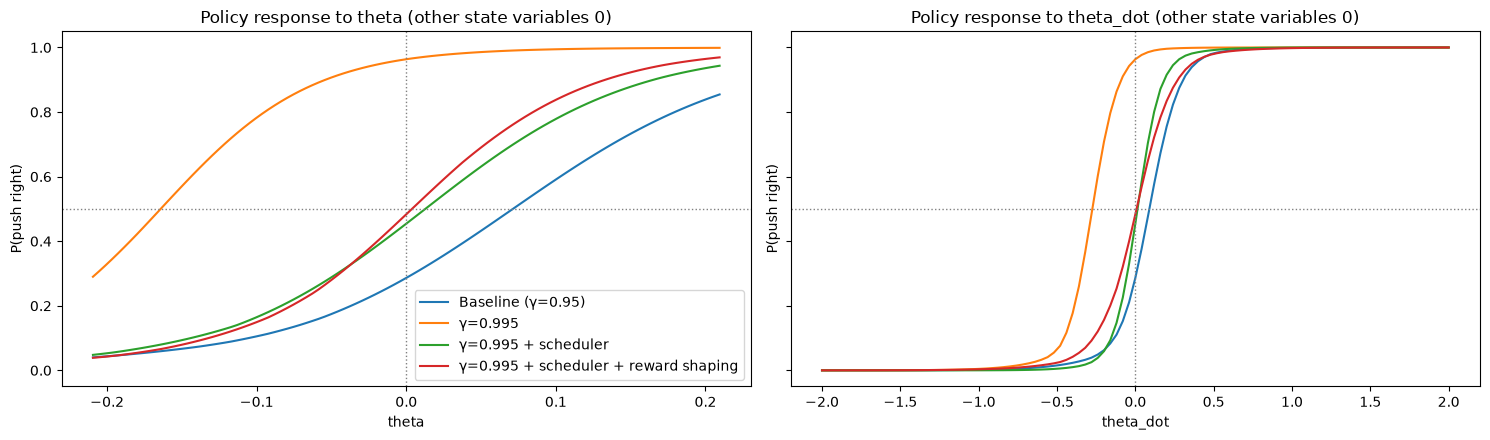

In [ ]:
SWEEPS = {"theta": (2, THETA_THRESHOLD), "theta_dot": (3, 2.0)}

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for ax, (label, (index, limit)) in zip(axes, SWEEPS.items()):
    values = np.linspace(-limit, limit, 101)
    states = np.zeros((len(values), 4), dtype=np.float32)
    states[:, index] = values
    for name, policy in policies.items():
        with torch.no_grad():
            p_right = F.sigmoid(policy(torch.tensor(states))).squeeze(1).numpy()
        ax.plot(values, p_right, label=name)
        report(
            f"{name}: P(right) increases with {label}, < 0.5 at {-limit:.2f} and > 0.5 at {limit:.2f}",
            np.all(np.diff(p_right) >= -1e-6) and p_right[0] < 0.5 < p_right[-1],
        )
    ax.axhline(0.5, color="gray", linestyle=":", linewidth=1)
    ax.axvline(0, color="gray", linestyle=":", linewidth=1)
    ax.set(
        xlabel=label,
        ylabel="P(push right)",
        title=f"Policy response to {label} (other state variables 0)",
    )
axes[0].legend()
fig.tight_layout()
save_figure(fig, "policy_response")
plt.show()

### Check 5: Harder Evaluation

The greedy evaluation above reaches the limit of 500 for every variant, so it cannot tell them apart. Two harder settings:
- **Sampled actions** (as during training) instead of always taking the more likely action.
- **Wider start states**, uniform in $[-0.2, 0.2]$ for every state variable instead of $[-0.15, 0.15]$. A pole starting at $\theta = 0.2$ is only 0.01 rad from falling.

**Expected:** the rewards drop below 500, and the differences between the variants become visible.


  0%|          | 0/500 [00:00<?, ?it/s]


  1%|          | 3/500 [00:00<00:18, 26.53it/s]


  1%|          | 6/500 [00:00<00:18, 26.85it/s]


  2%|▏         | 9/500 [00:00<00:18, 26.40it/s]


  2%|▏         | 12/500 [00:00<00:18, 25.94it/s]

...


 98%|█████████▊| 492/500 [00:16<00:00, 28.61it/s]


 99%|█████████▉| 495/500 [00:16<00:00, 28.86it/s]


100%|█████████▉| 498/500 [00:17<00:00, 28.45it/s]


100%|██████████| 500/500 [00:17<00:00, 29.16it/s]

Variant                                        Greedy, start ±0.15      Sampled, start ±0.15        Greedy, start ±0.2
Baseline (γ=0.95)                                    500.0 ± 0.0               482.2 ± 75.5              500.0 ± 0.0  
γ=0.995                                              500.0 ± 0.0               475.0 ± 104.9             486.7 ± 78.2 
γ=0.995 + scheduler                                  500.0 ± 0.0               484.6 ± 62.2              500.0 ± 0.0  
γ=0.995 + scheduler + reward shaping                 500.0 ± 0.0               492.5 ± 52.8              500.0 ± 0.0  


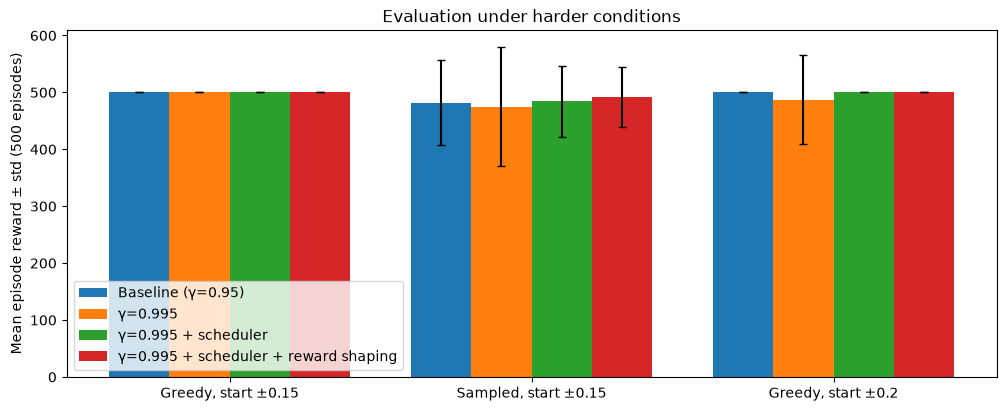

In [ ]:
WIDE_OPTIONS = {"low": -0.2, "high": 0.2}

settings = {
    "Greedy, start ±0.15": eval_results,
    "Sampled, start ±0.15": {
        name: evaluate(p, greedy=False) for name, p in policies.items()
    },
    "Greedy, start ±0.2": {
        name: evaluate(p, options=WIDE_OPTIONS) for name, p in policies.items()
    },
}

print(f"{'Variant':<40}" + "".join(f"{s:>26}" for s in settings))
for name in VARIANTS:
    print(
        f"{name:<40}"
        + "".join(
            f"{r[name]['reward'].mean():>18.1f} ± {r[name]['reward'].std():<5.1f}"
            for r in settings.values()
        )
    )

fig, ax = plt.subplots(figsize=(12, 4.5))
width = 0.8 / len(VARIANTS)
for i, name in enumerate(VARIANTS):
    means = [r[name]["reward"].mean() for r in settings.values()]
    stds = [r[name]["reward"].std() for r in settings.values()]
    ax.bar(
        np.arange(len(settings)) + i * width,
        means,
        width,
        yerr=stds,
        capsize=3,
        label=name,
    )
ax.set_xticks(
    np.arange(len(settings)) + width * (len(VARIANTS) - 1) / 2, list(settings)
)
ax.set(
    ylabel=f"Mean episode reward ± std ({EVAL_EPISODES} episodes)",
    title="Evaluation under harder conditions",
)
ax.legend(loc="lower left")
save_figure(fig, "robustness")
plt.show()

### Check 6: Why Do Episodes End? (Effect of $\gamma$ and Reward Shaping on the Cart Position)

An episode ends when the pole falls ($|\theta| > 12°$), when the cart leaves the track ($|x| > 2.4$), or at the time limit of 500 steps.
Check 1 showed that $\gamma = 0.95$ barely punishes a failure that happens more than ~60 steps later. A slow drift of the cart is exactly such a failure.
**Expected:**
- During training, many more episodes end because the cart leaves the track with $\gamma = 0.95$ than with $\gamma = 0.995$.
- Reward shaping explicitly pays for staying centered, so this variant has the fewest cart failures during training and keeps the cart closest to the center in the evaluation.

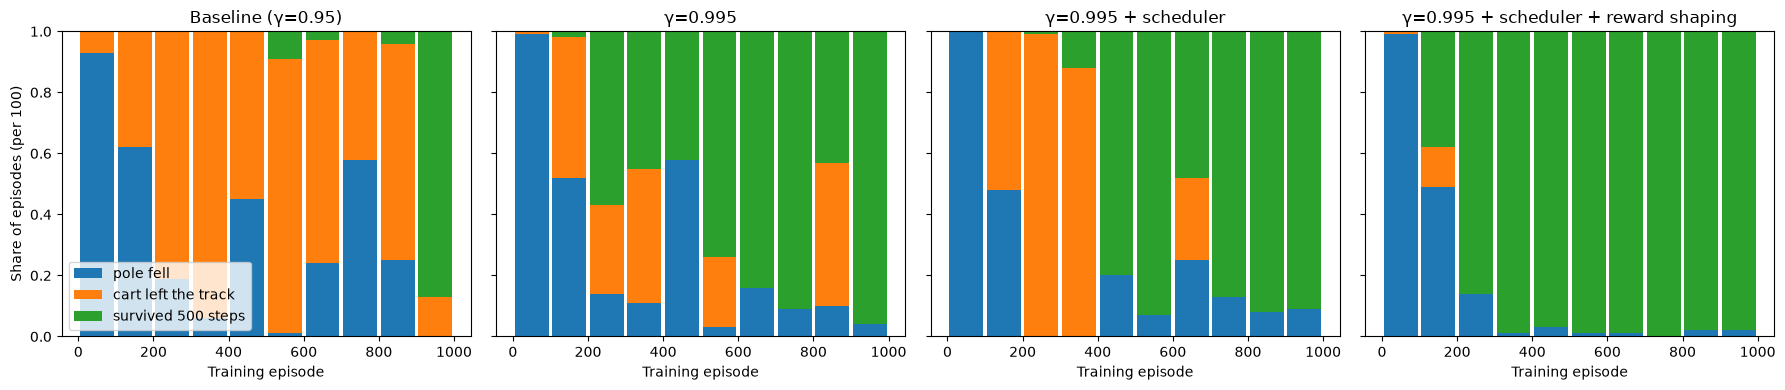

Variant                                    Training: cart / pole / 500   Sampled eval: cart / pole / 500   max |x| (sampled)
Baseline (γ=0.95)                                      564 / 333 / 103                      0 / 33 / 467                0.66
γ=0.995                                                190 / 276 / 534                      0 / 27 / 473                1.25
γ=0.995 + scheduler                                    266 / 230 / 504                      0 / 43 / 457                0.68
γ=0.995 + scheduler + reward shaping                    14 / 172 / 814                      0 / 11 / 489                0.26
Baseline (γ=0.95): greedy episode ends at x = +0.25
γ=0.995: greedy episode ends at x = -1.26
γ=0.995 + scheduler: greedy episode ends at x = -0.26
γ=0.995 + scheduler + reward shaping: greedy episode ends at x = -0.10


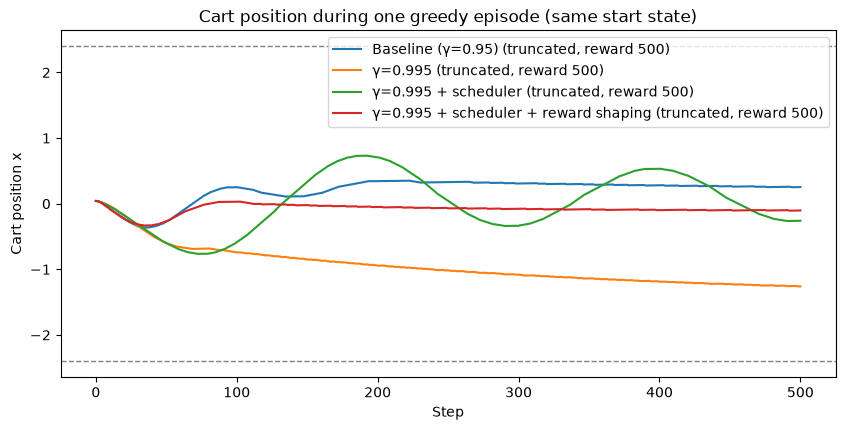

[PASS] Training: the cart leaves the track more often with γ = 0.95 (564) than with γ = 0.995 (190)
[PASS] Training: reward shaping has the fewest cart failures
[PASS] Evaluation: reward shaping keeps the cart closest to the center (median max |x|, sampled actions)


In [ ]:
REASONS = ["pole", "cart", "truncated"]
BIN = 100

fig, axes = plt.subplots(1, len(VARIANTS), figsize=(18, 4), sharey=True)
for ax, (name, ends) in zip(axes, train_ends.items()):
    ends = np.array(ends).reshape(-1, BIN)
    bottom = np.zeros(len(ends))
    for reason in REASONS:
        share = (ends == reason).mean(axis=1)
        ax.bar(
            np.arange(len(ends)) * BIN + BIN / 2,
            share,
            BIN * 0.9,
            bottom=bottom,
            label=reason,
        )
        bottom += share
    ax.set(xlabel="Training episode", title=name)
axes[0].set_ylabel(f"Share of episodes (per {BIN})")
axes[0].legend(
    ["pole fell", "cart left the track", "survived 500 steps"], loc="lower left"
)
fig.tight_layout()
save_figure(fig, "end_reasons")
plt.show()

print(
    f"{'Variant':<40}{'Training: cart / pole / 500':>30}{'Sampled eval: cart / pole / 500':>34}{'max |x| (sampled)':>20}"
)
sampled = settings["Sampled, start ±0.15"]
for name in VARIANTS:
    train_counts = " / ".join(
        str(train_ends[name].count(r)) for r in ("cart", "pole", "truncated")
    )
    eval_counts = " / ".join(
        str(np.sum(sampled[name]["end"] == r)) for r in ("cart", "pole", "truncated")
    )
    print(
        f"{name:<40}{train_counts:>30}{eval_counts:>34}{np.median(sampled[name]['max_x']):>20.2f}"
    )

env = gym.make("CartPole-v1")
fig, ax = plt.subplots(figsize=(10, 4.5))
for name, policy in policies.items():
    states, reward, end = rollout(env, policy, SEED, greedy=True)
    ax.plot(states[:, 0], label=f"{name} ({end}, reward {reward:.0f})")
    print(f"{name}: greedy episode ends at x = {states[-1, 0]:+.2f}")
for limit in (-X_THRESHOLD, X_THRESHOLD):
    ax.axhline(limit, color="gray", linestyle="--", linewidth=1)
ax.set(
    xlabel="Step",
    ylabel="Cart position x",
    title="Cart position during one greedy episode (same start state)",
)
ax.legend()
save_figure(fig, "cart_position")
plt.show()

cart_failures = {name: train_ends[name].count("cart") for name in VARIANTS}
report(
    f"Training: the cart leaves the track more often with γ = 0.95 ({cart_failures[BASELINE]}) than with γ = 0.995 ({cart_failures['γ=0.995']})",
    cart_failures[BASELINE] > cart_failures["γ=0.995"],
)
report(
    "Training: reward shaping has the fewest cart failures",
    min(cart_failures, key=cart_failures.get) == FULL,
)
report(
    "Evaluation: reward shaping keeps the cart closest to the center (median max |x|, sampled actions)",
    min(VARIANTS, key=lambda n: np.median(sampled[n]["max_x"])) == FULL,
)

### Edge-Case Checks
- **Invalid inputs:** `episodes <= 0`, $\gamma \notin (0, 1]$ and a scheduler that wraps a different optimizer are rejected with a `ValueError`.
  $\gamma = 0$ is rejected because then every return is the immediate reward of 1, so the policy gets no signal about survival.
- **Scheduler:** it is stepped once per episode with `T_max = episodes`, so the learning rate must end exactly at `ETA_MIN`.
- **Reward shaping:** the shaped reward must be positive everywhere on the track. Otherwise ending an episode early could become attractive.
- **Time limit:** CartPole-v1 truncates at 500 steps. Every evaluation reward of 500 must be a truncation, never a failure, and no reward can exceed 500.
- **Reproducibility:** training twice with the same seed must give identical results.

In [ ]:
env = gym.make("CartPole-v1")
policy = Policy(HIDDEN)
optimizer = optim.Adam(policy.parameters(), lr=LEARNING_RATE)
foreign_scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optim.Adam(Policy(HIDDEN).parameters()), T_max=1
)
invalid = {
    "episodes = 0": {"episodes": 0, "gamma": GAMMA},
    "γ = 0": {"episodes": 1, "gamma": 0.0},
    "γ = 1.5": {"episodes": 1, "gamma": 1.5},
    "a scheduler of another optimizer": {
        "episodes": 1,
        "gamma": GAMMA,
        "scheduler": foreign_scheduler,
    },
}
for label, kwargs in invalid.items():
    try:
        train(env, policy, optimizer, **kwargs)
        raised = False
    except ValueError:
        raised = True
    report(f"Rejects {label}", raised)

scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=5, eta_min=ETA_MIN)
train(env, policy, optimizer, 5, GAMMA, scheduler=scheduler)
final_lr = optimizer.param_groups[0]["lr"]
report(
    f"Scheduler: learning rate after T_max episodes = {final_lr:.4f} = ETA_MIN",
    np.isclose(final_lr, ETA_MIN),
)

positions = np.linspace(-X_THRESHOLD, X_THRESHOLD, 201)
shaped = np.array([shape_reward(1.0, [x, 0, 0, 0]) for x in positions])
print(
    f"Shaped reward: {shaped.max():.4f} at x = 0, {shaped[0]:.4f} at |x| = {X_THRESHOLD}"
)
report(
    "Shaped reward is positive on the whole track and largest at the center",
    shaped.min() > 0 and positions[shaped.argmax()] == 0,
)

all_results = [r for setting in settings.values() for r in setting.values()]
report(
    "No evaluation reward exceeds 500",
    all(np.all(r["reward"] <= 500) for r in all_results),
)
report(
    "Every evaluation reward of 500 is a truncation, every shorter episode a failure",
    all(
        np.array_equal(r["reward"] == 500, r["end"] == "truncated") for r in all_results
    ),
)

_, first, _ = run_variant(GAMMA, episodes=20)
_, second, _ = run_variant(GAMMA, episodes=20)
report("Same seed gives identical training rewards", first == second)

[PASS] Rejects episodes = 0
[PASS] Rejects γ = 0
[PASS] Rejects γ = 1.5
[PASS] Rejects a scheduler of another optimizer



  0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 5/5 [00:00<00:00, 113.59it/s]

[PASS] Scheduler: learning rate after T_max episodes = 0.0010 = ETA_MIN
Shaped reward: 0.5699 at x = 0, 0.0016 at |x| = 2.4
[PASS] Shaped reward is positive on the whole track and largest at the center
[PASS] No evaluation reward exceeds 500
[PASS] Every evaluation reward of 500 is a truncation, every shorter episode a failure



  0%|          | 0/20 [00:00<?, ?it/s]

...


100%|██████████| 20/20 [00:00<00:00, 106.64it/s]


  0%|          | 0/20 [00:00<?, ?it/s]


 60%|██████    | 12/20 [00:00<00:00, 111.92it/s]


100%|██████████| 20/20 [00:00<00:00, 109.74it/s]

[PASS] Same seed gives identical training rewards


## Visual Rollout

In [24]:
policy = policies["γ=0.995 + scheduler + reward shaping"]
simulation = gym.make("CartPole-v1", render_mode="human", max_episode_steps=500)
state, _ = simulation.reset(options={"low": -0.2, "high": 0.2})

policy.eval()
done = False
steps = 0
while not done:
    with torch.no_grad():
        logit = policy(torch.tensor(state))
    action = int(logit.item() > 0)
    state, _, terminated, truncated, _ = simulation.step(action)
    done = terminated or truncated
    steps += 1

print(f"Survived {steps} steps")
simulation.close()

Survived 500 steps


Screenshot:
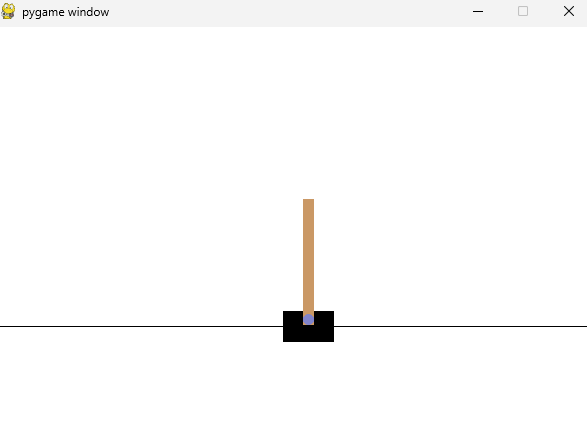